Import gambar

In [ ]:
import cv2
import matplotlib.pyplot as plt
import zipfile
import os
import glob

# 1. Ekstrak file dataset ZIP secara langsung
zip_path = '/content/cars-object-detection.zip'
extract_path = '/content/cars_dataset'

with zipfile.ZipFile(zip_path, 'r') as zip_ref:
    zip_ref.extractall(extract_path)

print("Dataset berhasil diekstrak ke:", extract_path)

# 2. Cari semua file gambar di dalam folder hasil ekstraksi
image_extensions = ('*.png', '*.jpg', '*.jpeg', '*.PNG', '*.JPG', '*.JPEG')
image_files = []
for ext in image_extensions:
    image_files.extend(glob.glob(os.path.join(extract_path, '**', ext), recursive=True))

if len(image_files) > 0:
    # Ambil gambar pertama sebagai contoh untuk diproses di tahap berikutnya
    image_path = image_files[0]
    print(f"Menggunakan gambar: {image_path}")

    # 3. Baca gambar menggunakan OpenCV
    img_bgr = cv2.imread(image_path)
    img_rgb = cv2.cvtColor(img_bgr, cv2.COLOR_BGR2RGB)
else:
    print("Tidak ditemukan file gambar di dalam ZIP yang diekstrak.")

Dataset berhasil diekstrak ke: /content/cars_dataset
Menggunakan gambar: /content/cars_dataset/train/train/images/f92cc929-GOPR6604.JPG


Grayscale

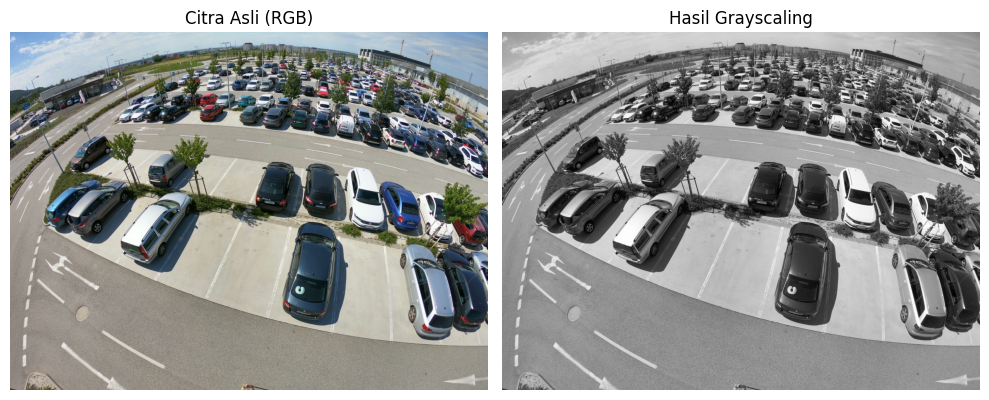

In [ ]:
# Melakukan konversi citra asli (BGR) ke Grayscale
img_gray = cv2.cvtColor(img_bgr, cv2.COLOR_BGR2GRAY)

# Menampilkan perbandingan citra asli dengan hasil grayscaling
plt.figure(figsize=(10, 5))

plt.subplot(1, 2, 1)
plt.imshow(img_rgb)
plt.title('Citra Asli (RGB)')
plt.axis('off')

plt.subplot(1, 2, 2)
plt.imshow(img_gray, cmap='gray')
plt.title('Hasil Grayscaling')
plt.axis('off')

plt.tight_layout()
plt.show()

Image Enhancement (HE, CS, CLAHE)

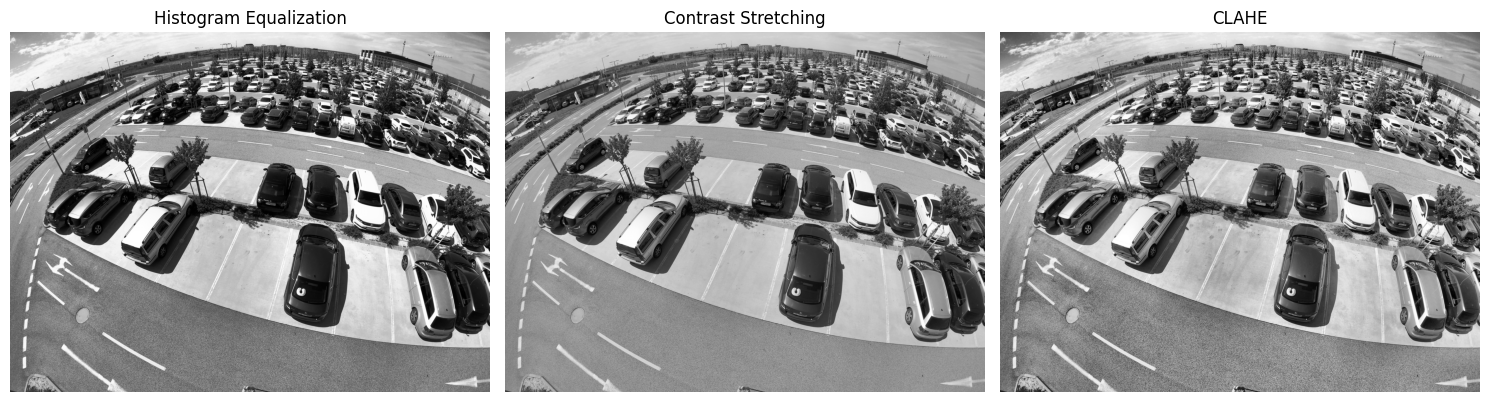

In [ ]:
# 1. Histogram Equalization (HE)
img_he = cv2.equalizeHist(img_gray)

# 2. Contrast Stretching (CS)
img_cs = cv2.normalize(img_gray, None, alpha=0, beta=255, norm_type=cv2.NORM_MINMAX)

# 3. CLAHE (Contrast Limited Adaptive Histogram Equalization)
clahe = cv2.createCLAHE(clipLimit=2.0, tileGridSize=(8, 8))
img_clahe = clahe.apply(img_gray)

# Menampilkan perbandingan hasil enhancement
fig, axes = plt.subplots(1, 3, figsize=(15, 5))
axes[0].imshow(img_he, cmap='gray')
axes[0].set_title('Histogram Equalization')
axes[1].imshow(img_cs, cmap='gray')
axes[1].set_title('Contrast Stretching')
axes[2].imshow(img_clahe, cmap='gray')
axes[2].set_title('CLAHE')

for ax in axes:
    ax.axis('off')

plt.tight_layout()
plt.show()

Median Filter

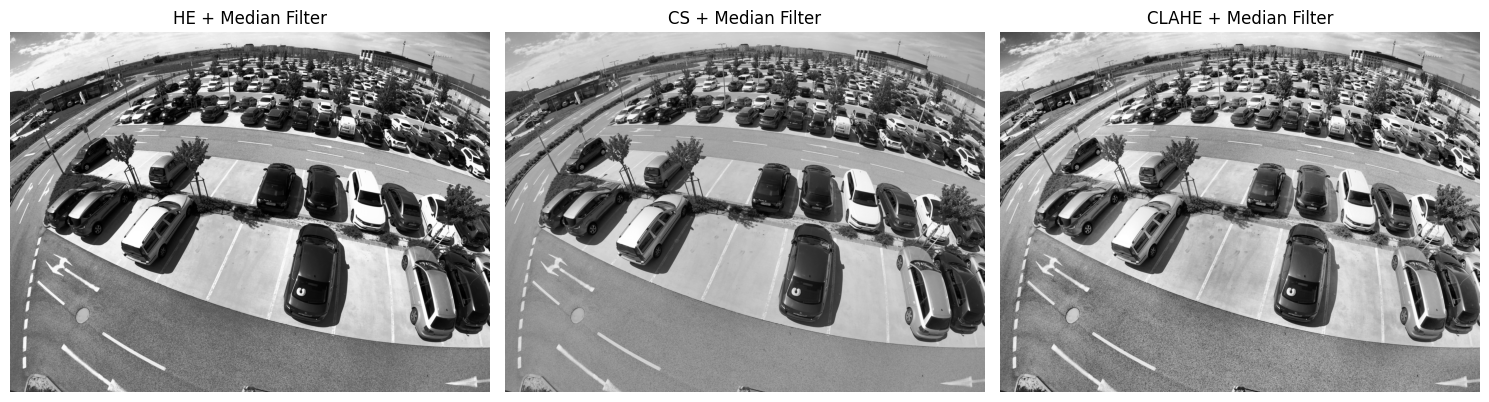

In [ ]:
# Menerapkan Median Filter ke 3 citra hasil enhancement sebelumnya
filter_he = cv2.medianBlur(img_he, 5)
filter_cs = cv2.medianBlur(img_cs, 5)
filter_clahe = cv2.medianBlur(img_clahe, 5)

# Menampilkan perbandingan hasil setelah di-filter
fig, axes = plt.subplots(1, 3, figsize=(15, 5))
axes[0].imshow(filter_he, cmap='gray')
axes[0].set_title('HE + Median Filter')
axes[1].imshow(filter_cs, cmap='gray')
axes[1].set_title('CS + Median Filter')
axes[2].imshow(filter_clahe, cmap='gray')
axes[2].set_title('CLAHE + Median Filter')

for ax in axes:
    ax.axis('off')

plt.tight_layout()
plt.show()

Evaluasi MSE dan PSNR

In [ ]:
import numpy as np

def calculate_mse(image_a, image_b):
    # Menghitung Mean Squared Error (MSE)
    err = np.sum((image_a.astype("float") - image_b.astype("float")) ** 2)
    err /= float(image_a.shape[0] * image_a.shape[1])
    return err

def calculate_psnr(image_a, image_b):
    mse = calculate_mse(image_a, image_b)
    if mse == 0:
        return float('inf')
    # Nilai piksel maksimum untuk citra 8-bit adalah 255
    max_pixel = 255.0
    psnr = 20 * np.log10(max_pixel / np.sqrt(mse))
    return psnr

# Evaluasi perbandingan citra Grayscale asli dengan hasil filter
mse_median = calculate_mse(img_gray, filter_clahe)
psnr_median = calculate_psnr(img_gray, filter_clahe)

mse_gaussian = calculate_mse(img_gray, filter_gaussian)
psnr_gaussian = calculate_psnr(img_gray, filter_gaussian)

print("=== HASIL EVALUASI METRIK ===\n")
print(f"1. CLAHE + Median Filter:")
print(f"   - MSE  : {mse_median:.2f}")
print(f"   - PSNR : {psnr_median:.2f} dB\n")
print(f"2. CLAHE + Gaussian Filter:")
print(f"   - MSE  : {mse_gaussian:.2f}")
print(f"   - PSNR : {psnr_gaussian:.2f} dB")

=== HASIL EVALUASI METRIK ===

1. CLAHE + Median Filter:
   - MSE  : 368.77
   - PSNR : 22.46 dB

2. CLAHE + Gaussian Filter:
   - MSE  : 316.81
   - PSNR : 23.12 dB


Deteksi Tepi (Sobel & Roberts)

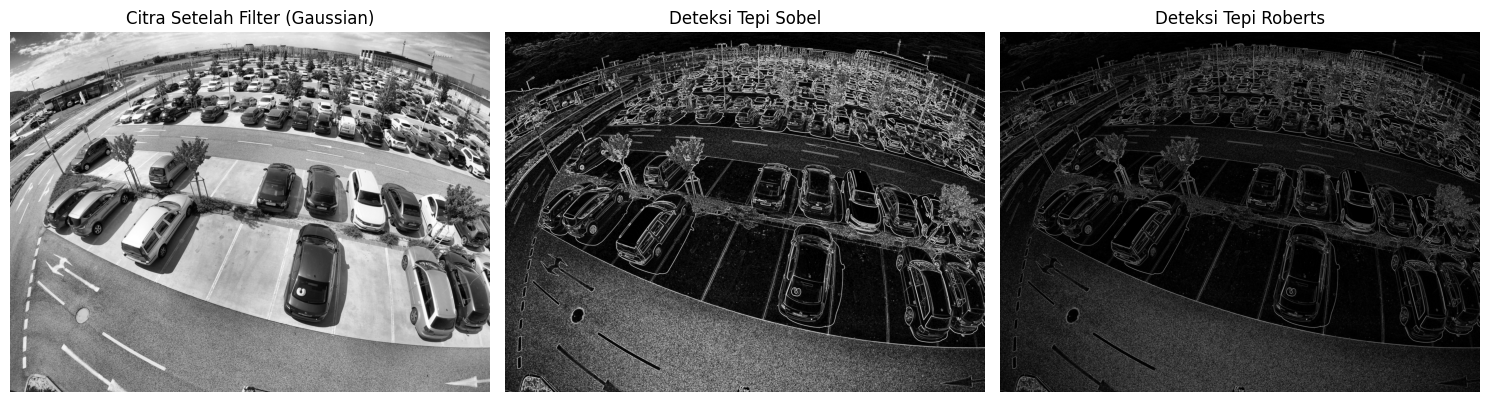

In [ ]:
import numpy as np
import cv2
import matplotlib.pyplot as plt

# 1. Deteksi Tepi Sobel
# Sobel X (gradien horizontal)
sobel_x = cv2.Sobel(filter_gaussian, cv2.CV_64F, 1, 0, ksize=3)
# Sobel Y (gradien vertikal)
sobel_y = cv2.Sobel(filter_gaussian, cv2.CV_64F, 0, 1, ksize=3)
# Gabungkan kedua gradien (magnitudo)
edge_sobel = np.sqrt(sobel_x**2 + sobel_y**2)
edge_sobel = np.uint8(np.clip(edge_sobel, 0, 255))

# 2. Deteksi Tepi Roberts
# Kernel Roberts Cross
kernel_roberts_x = np.array([[1, 0], [0, -1]], dtype=np.float32)
kernel_roberts_y = np.array([[0, 1], [-1, 0]], dtype=np.float32)
# Terapkan filter
roberts_x = cv2.filter2D(filter_gaussian, cv2.CV_64F, kernel_roberts_x)
roberts_y = cv2.filter2D(filter_gaussian, cv2.CV_64F, kernel_roberts_y)
# Gabungkan kedua gradien (magnitudo)
edge_roberts = np.sqrt(roberts_x**2 + roberts_y**2)
edge_roberts = np.uint8(np.clip(edge_roberts, 0, 255))

# Menampilkan perbandingan hasil deteksi tepi
plt.figure(figsize=(15, 6))

plt.subplot(1, 3, 1)
plt.imshow(filter_gaussian, cmap='gray')
plt.title('Citra Setelah Filter (Gaussian)')
plt.axis('off')

plt.subplot(1, 3, 2)
plt.imshow(edge_sobel, cmap='gray')
plt.title('Deteksi Tepi Sobel')
plt.axis('off')

plt.subplot(1, 3, 3)
plt.imshow(edge_roberts, cmap='gray')
plt.title('Deteksi Tepi Roberts')
plt.axis('off')

plt.tight_layout()
plt.show()